# Классификация: качество кофе (`archive.zip`)
Предсказываем `quality_grade` (5 классов: Commercial, Good, Very Good, Excellent, Exceptional).
Шаги: пропуски, категориальные переменные, логистическая регрессия, метрики.

In [1]:
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.metrics
from sklearn.model_selection import train_test_split # функция, чтобы разбить данные на трейн и тест
from sklearn.linear_model import LogisticRegression # наша модель для классификации
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

## Загрузка данных

In [2]:
# архив лежит рядом с ноутбуком
df = pd.read_csv(zipfile.ZipFile('archive.zip').open('coffee_value_benchmark.csv'))
df = df.drop_duplicates(subset='lot_id') # убираем повторные записи одной и той же партии
df.head()

     record_id       lot_id  ... quality_grade  price_usd_per_kg
0  REC-0000001  LOT-0032936  ...     Very Good              2.43
1  REC-0000002  LOT-0030952  ...          Good              4.06
2  REC-0000003  LOT-0018572  ...    Commercial              4.26
3  REC-0000004  LOT-0005318  ...          Good              3.60
4  REC-0000005  LOT-0006317  ...          Good              4.16

[5 rows x 36 columns]

In [3]:
df.shape

(35000, 36)

## Целевая переменная и признаки
Из признаков убираем всё, что «подсказывает» ответ (оценки вкуса, итоговый балл, цена), и служебные столбцы.

In [4]:
Y = df['quality_grade']   # целевая переменная
X = df.drop(columns=['quality_grade', 'coffee_quality_score', 'price_usd_per_kg',
                     'acidity_score', 'sweetness_score', 'body_score', 'aroma_score', 'flavor_score',
                     'record_id', 'lot_id',
                     'roast_level', 'traceability_level', 'certification',
                     'intended_buyer_segment', 'lot_size_kg'])
X.head()

  harvest_season  harvest_calendar_year  ...  bean_density_g_ml defect_rate_pct
0        2020/21                   2020  ...              1.165             3.6
1        2021/22                   2022  ...              1.112             4.9
2        2020/21                   2020  ...              1.094             0.0
3        2021/22                   2021  ...              1.100             0.8
4        2021/22                   2021  ...              1.095             2.5

[5 rows x 21 columns]

In [5]:
Y.value_counts()

quality_grade
Very Good      12250
Good            7000
Commercial      7000
Excellent       7000
Exceptional     1750
Name: count, dtype: int64

## Обработка категориальных переменных
Модель работает только с числами, поэтому текстовые столбцы (страна, тип фермы, метод обработки...) превращаем в 0/1 столбцы через `get_dummies` (one-hot).

In [6]:
X = pd.get_dummies(X)
X.shape

(35000, 40)

## Обработка пропусков
Смотрим, где есть пропуски.

In [7]:
X.isna().sum()[X.isna().sum() > 0]

avg_annual_rainfall_mm    1777
humidity_pct              2239
moisture_pct              1587
bean_density_g_ml         1607
dtype: int64

Пропуски только в 4 числовых столбцах (~5%). Удалять строки жалко, поэтому заполним медианой. Медиану считаем по train, поэтому сначала разбиваем данные.

In [8]:
X_train, X_val, Y_train, Y_val = train_test_split(X, Y, test_size = 0.3, random_state = 42)

# пропуски -> медиана по train
median = X_train.median()
X_train = X_train.fillna(median)
X_val = X_val.fillna(median)
X_train.isna().sum().sum(), X_val.isna().sum().sum()

(np.int64(0), np.int64(0))

Приводим числа к одному масштабу, чтобы логистическая регрессия лучше обучалась.

In [9]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

## Логистическая регрессия

In [10]:
model = LogisticRegression(max_iter = 1000)
model.fit(X_train, Y_train)

LogisticRegression(max_iter=1000)

## Метрики
Классов больше двух, поэтому precision, recall и f1 усредняем по классам (`average='macro'`).

In [11]:
Y_predicted = model.predict(X_val)
print(accuracy_score(Y_val,Y_predicted))
print(precision_score(Y_val,Y_predicted, average='macro'))
print(recall_score(Y_val,Y_predicted, average='macro'))
print(f1_score(Y_val,Y_predicted, average='macro'))

0.6832380952380952
0.6882554230178128
0.629327523478525
0.6486542828916623

In [12]:
r = sklearn.metrics.confusion_matrix(Y_val, Y_predicted, labels=model.classes_)
print(model.classes_)
print(r)

['Commercial' 'Excellent' 'Exceptional' 'Good' 'Very Good']
[[1703    0    0  314   58]
 [   0 1291   85    7  735]
 [   0  272  226    2   34]
 [ 474    3    0 1061  552]
 [  10  474    1  305 2893]]

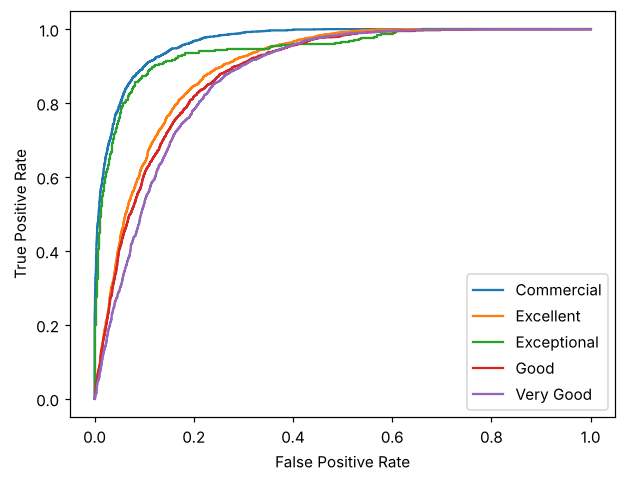

In [13]:
# ROC-кривая для каждого класса (класс против остальных)
proba = model.predict_proba(X_val)

for i, name in enumerate(model.classes_):
    fpr, tpr, _ = sklearn.metrics.roc_curve(Y_val == name, proba[:, i])
    plt.plot(fpr, tpr, label=name)

plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend()
plt.show()